## M2 MobileNet OOD
The purpose of this notebook will be to try and change the MobileNet head to transfer learn it from ImageNet to CIFAR10 dataset. The aim is to implement a simple out-of-distribution (OOD) detection method using many different techniques and then test if it actually does something

<div style="text-align: center;">
<img src="https://www.researchgate.net/publication/376752661/figure/fig3/AS:11431281213995739@1703264754673/MobileNet-V1-architecture.png" width="900" alt="Mobile Net Architecture">
</div>

## 1. Setup
Import necessary libraries and set up the environment for training and evaluating the MobileNet model on the CIFAR10 dataset.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights
from torch.utils.data import DataLoader
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

### 1.1 Device Configuration
Set up the device for training (GPU if available, otherwise CPU).

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


### 1.2 Getting training and testing dataset
Because MobileNet is pretrained on ImageNet, we need to resize the CIFAR10 images from 32x32 to 224x224 and normalize them using ImageNet's mean and std.

In [3]:
transform = transforms.Compose([
    transforms.Resize(224),  # MobileNet expects 224x224 images
    transforms.ToTensor(),  # Convert PIL image to tensor
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # ImageNet normalization
])

train_dataset_id = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
test_dataset_id = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

train_loader_id = DataLoader(train_dataset_id, batch_size=64, shuffle=True, num_workers=2)
test_loader_id = DataLoader(test_dataset_id, batch_size=64, shuffle=False, num_workers=2)

100%|██████████| 170M/170M [00:03<00:00, 43.1MB/s]


In [4]:
print(f"Number of training samples: {len(train_dataset_id)}")
print(f"Number of test samples: {len(test_dataset_id)}")

Number of training samples: 50000
Number of test samples: 10000


### 1.3 Getting the OOD dataset
For OOD detection, we will use the SVHN dataset and CIFAR100 as our out-of-distribution data

In [5]:
ood_dataset_cifar100 = torchvision.datasets.CIFAR100(root='./data', train=False, download=True, transform=transform)
ood_loader_cifar100 = DataLoader(ood_dataset_cifar100, batch_size=64, shuffle=False, num_workers=2)
print(f"Amount of CIFAR100 samples (OOD - CIFAR-100): {len(ood_dataset_cifar100)}")

100%|██████████| 169M/169M [00:04<00:00, 41.7MB/s]


Amount of CIFAR100 samples (OOD - CIFAR-100): 10000


In [6]:
ood_dataset_svhn = torchvision.datasets.SVHN(root='./data', split='test', download=True, transform=transform)
ood_loader_svhn = DataLoader(ood_dataset_svhn, batch_size=64, shuffle=False, num_workers=2)
print(f"Amount of SVHN samples (OOD - SVHN): {len(ood_dataset_svhn)}")

100%|██████████| 64.3M/64.3M [00:01<00:00, 56.4MB/s]


Amount of SVHN samples (OOD - SVHN): 26032


### 1.4 Getting the model
For our test we will use MobileNet V3 Small pretrained on ImageNet

We will need to do the following:
- Load the pretrained MobileNet V3 Small model
- Freeze the feature extractor layers
- Replace the classifier head to output 10 classes for CIFAR-10

<div style="text-align: center;">
<img src="https://www.nim.org/fileadmin/PUBLIC/2_NIM_Forschung/mobilelogoshootout.png" width="900" alt="MobileNet vs Yolo">
</div>

In [7]:
model = mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.IMAGENET1K_V1)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 121MB/s]


In [8]:
for param in model.parameters():
    param.requires_grad = False

In [9]:
num_features = model.classifier[-1].in_features # Get the number of input features to the last layer
model.classifier[-1] = nn.Linear(num_features, 10) # Create a new linear layer with 10 outputs for CIFAR-10 and num_features inputs

In [10]:
model = model.to(device)

## 2. Training the model
Set up the training loop to fine-tune the MobileNet model on the CIFAR-10 dataset.

### 2.1 Loss function and optimizer
Use Cross-Entropy Loss and Adam optimizer for training the model.

In [11]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.classifier.parameters(), lr=0.001)

### 2.2 Training loop

In [14]:
epochs = 7

In [15]:
for epoch in range(epochs):
    model.train()

    running_loss = 0.0
    progress_bar = tqdm(train_loader_id, desc=f"Epochs {epoch+1}/{epochs}")

    for inputs, labels in progress_bar:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        progress_bar.set_postfix(loss=running_loss / (progress_bar.n + 1))

    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {running_loss/len(train_loader_id):.4f}")

    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in test_loader_id:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    print(f"Test Accuracy of the model on the 10000 test images: {accuracy:.2f}%")

Epochs 1/7: 100%|██████████| 782/782 [01:28<00:00,  8.82it/s, loss=0.495]


Test Accuracy of the model on the 10000 test images: 84.10%


Epochs 2/7: 100%|██████████| 782/782 [01:25<00:00,  9.13it/s, loss=0.493]


Test Accuracy of the model on the 10000 test images: 84.11%


Epochs 3/7: 100%|██████████| 782/782 [01:25<00:00,  9.12it/s, loss=0.483]


...

Test Accuracy of the model on the 10000 test images: 84.18%


Epochs 6/7: 100%|██████████| 782/782 [01:25<00:00,  9.10it/s, loss=0.475]


Test Accuracy of the model on the 10000 test images: 84.59%


Epochs 7/7: 100%|██████████| 782/782 [01:25<00:00,  9.15it/s, loss=0.476]


Test Accuracy of the model on the 10000 test images: 84.23%


## 3. OOD Detection
Implement simple OOD detection methods using the trained MobileNet model.

### 3.1 Energy-Based Scoring
Define a function to compute energy scores for OOD detection.
<div style="text-align: center;">
<img src="https://cherrypicked.dev/content/images/2020/10/Screen-Shot-2020-10-20-at-8.36.37-PM.png" width="900" alt="Energy Based OOD Detection">
</div>

In [16]:
def get_energy_score(logits, T=1.0):
    """
    Compute the energy score for given logits.
    Lower energy indicates in-distribution.
    Higher energy indicates out-of-distribution.
    :param logits: Tensor of shape (N, C) where N is batch size and C is number of classes
    :param T: Temperature scaling parameter
    :return: Tensor of shape (N,) containing energy scores
    """
    energy = -T * torch.logsumexp(logits / T, dim=1)
    return energy

In [17]:
def get_scores_for_loader(loader, model):
    model.eval()
    all_scores = []
    with torch.no_grad():
        for inputs, _ in tqdm(loader, desc="Získávám OOD skóre"):
            inputs = inputs.to(device)
            logits = model(inputs)
            scores = get_energy_score(logits)
            all_scores.extend(scores.cpu().numpy())
    return np.array(all_scores)

In [18]:
print("\nCalculating OOD scores for ID and OOD datasets...")
id_scores = get_scores_for_loader(test_loader_id, model)
ood_scores_cifar100 = get_scores_for_loader(ood_loader_cifar100, model)
ood_scores_svhn = get_scores_for_loader(ood_loader_svhn, model)


Calculating OOD scores for ID and OOD datasets...


Získávám OOD skóre: 100%|██████████| 407/407 [00:46<00:00,  8.83it/s]


### 3.2 Testing the accuracy
- First we will get the threshold value from the highest 5%
- Then we evaluate it on our CIFAR test -> Should be in theory the 5% expected

In [19]:
threshold = np.percentile(id_scores, 95)
print(f"Treshold value selected for 95% TPR: {threshold: .4f}")

Treshold value selected for 95% TPR: -3.9816


In [20]:
misclassified_id_count = np.sum(id_scores > threshold)
total_id_count = len(id_scores)
misclassified_id_percent = (misclassified_id_count / total_id_count) * 100

In [21]:
print("--- Evaluation of CIFAR-10 Test Set ---")
print(f"Number of images flagged as OOD wrongly: {misclassified_id_count} z {total_id_count}")
print(f"False rejection rate: {misclassified_id_percent:.2f} %\n")

--- Evaluation of CIFAR-10 Test Set ---
Number of images flagged as OOD wrongly: 500 z 10000
False rejection rate: 5.00 %



### 3.2.1 CIFAR100 and SVHN respectively

In [22]:
detected_ood_cifar100_count = np.sum(ood_scores_cifar100 > threshold)
total_ood_cifar100_count = len(ood_scores_cifar100)
detection_rate_cifar100 = (detected_ood_cifar100_count / total_ood_cifar100_count) * 100

In [23]:
print("--- Evaluation of CIFAR-100 Set ---")
print(f"Number of objects correctly as OOD: {detected_ood_cifar100_count} z {total_ood_cifar100_count}")
print(f"Detection Rate: {detection_rate_cifar100:.2f} %\n")

--- Evaluation of CIFAR-100 Set ---
Number of objects correctly as OOD: 3132 z 10000
Detection Rate: 31.32 %



In [24]:
detected_ood_svhn_count = np.sum(ood_scores_svhn > threshold)
total_ood_svhn_count = len(ood_scores_svhn)
detection_rate_svhn = (detected_ood_svhn_count / total_ood_svhn_count) * 100

In [25]:
print("--- Evaluation of CIFAR-100 Set ---")
print(f"Number of objects correctly as OOD: {detected_ood_svhn_count} z {total_ood_svhn_count}")
print(f"Detection Rate: {detection_rate_svhn:.2f} %\n")

--- Evaluation of CIFAR-100 Set ---
Number of objects correctly as OOD: 14311 z 26032
Detection Rate: 54.97 %



## 4. Different methods


### 4.1. MSP

In [26]:
def get_msp_score(logits):
    """
    Computes the OOD score based on Maximum Softmax Probability.

    Returns (1 - max_softmax_prob). Similar to energy,
    a higher value means "more OOD" (lower model confidence).
    """
    probs = torch.softmax(logits, dim=1)

    max_probs, _ = torch.max(probs, dim=1)

    return 1 - max_probs

In [27]:
def get_scores_for_loader_generic(loader, model, score_function):
    model.eval()
    all_scores = []
    with torch.no_grad():
        for inputs, _ in tqdm(loader, desc=f"Getting score ({score_function.__name__})"):
            inputs = inputs.to(device)
            logits = model(inputs)
            scores = score_function(logits)
            all_scores.extend(scores.cpu().numpy())
    return np.array(all_scores)

In [28]:
id_scores_msp = get_scores_for_loader_generic(test_loader_id, model, get_msp_score)
ood_scores_cifar100_msp = get_scores_for_loader_generic(ood_loader_cifar100, model, get_msp_score)
ood_scores_svhn_msp = get_scores_for_loader_generic(ood_loader_svhn, model, get_msp_score)

Getting score (get_msp_score): 100%|██████████| 407/407 [00:43<00:00,  9.28it/s]


In [29]:
threshold_msp = np.percentile(id_scores_msp, 95)
print(f"Threshold for MSP: {threshold_msp:.4f}\n")

Threshold for MSP: 0.5488



In [30]:
misclassified_id_count_msp = np.sum(id_scores_msp > threshold_msp)
total_id_count_msp = len(id_scores_msp)
misclassified_id_percent_msp = (misclassified_id_count_msp / total_id_count_msp) * 100

print("--- Evaluation of MSP on In-Distribution Data (CIFAR-10 Test Set) ---")
print(f"Number of images wrongly flagged as OOD: {misclassified_id_count_msp} out of {total_id_count_msp}")
print(f"False Rejection Rate: {misclassified_id_percent_msp:.2f} %\n")

--- Evaluation of MSP on In-Distribution Data (CIFAR-10 Test Set) ---
Number of images wrongly flagged as OOD: 500 out of 10000
False Rejection Rate: 5.00 %



In [31]:
detected_ood_cifar100_count_msp = np.sum(ood_scores_cifar100_msp > threshold_msp)
total_ood_cifar100_count_msp = len(ood_scores_cifar100_msp)
detection_rate_cifar100_msp = (detected_ood_cifar100_count_msp / total_ood_cifar100_count_msp) * 100

print("--- Evaluation of MSP on Out-of-Distribution Data (CIFAR-100) ---")
print(f"Number of images correctly detected as OOD: {detected_ood_cifar100_count_msp} out of {total_ood_cifar100_count_msp}")
print(f"Detection Rate: {detection_rate_cifar100_msp:.2f} %\n")

--- Evaluation of MSP on Out-of-Distribution Data (CIFAR-100) ---
Number of images correctly detected as OOD: 2337 out of 10000
Detection Rate: 23.37 %



In [32]:
detected_ood_svhn_count_msp = np.sum(ood_scores_svhn_msp > threshold_msp)
total_ood_svhn_count_msp = len(ood_scores_svhn_msp)
detection_rate_svhn_msp = (detected_ood_svhn_count_msp / total_ood_svhn_count_msp) * 100

print("--- Evaluation of MSP on Out-of-Distribution Data (SVHN) ---")
print(f"Number of images correctly detected as OOD: {detected_ood_svhn_count_msp} out of {total_ood_svhn_count_msp}")
print(f"Detection Rate: {detection_rate_svhn_msp:.2f} %\n")

--- Evaluation of MSP on Out-of-Distribution Data (SVHN) ---
Number of images correctly detected as OOD: 9838 out of 26032
Detection Rate: 37.79 %



### 4.2 Monte Carlo Dropout
Monte Carlo Dropout is a technique where dropout is applied during inference to create an ensemble of predictions. This can help in estimating uncertainty and improving OOD detection.

In [33]:
def get_mc_dropout_scores(loader, model, n_passes=20):
    """
    Computes OOD score using Monte Carlo Dropout.
    We use predictive entropy as the score.
    """
    model.train()

    all_scores = []
    with torch.no_grad():
        for inputs, _ in tqdm(loader, desc=f"Getting MC Dropout scores ({n_passes} passes)"):
            inputs = inputs.to(device)

            batch_predictions = []
            for _ in range(n_passes):
                logits = model(inputs)
                softmax_preds = torch.softmax(logits, dim=1)
                batch_predictions.append(softmax_preds.unsqueeze(0))

            batch_predictions = torch.cat(batch_predictions, dim=0)

            mean_probs = torch.mean(batch_predictions, dim=0)

            epsilon = 1e-10
            entropy = -torch.sum(mean_probs * torch.log(mean_probs + epsilon), dim=1)

            all_scores.extend(entropy.cpu().numpy())

    return np.array(all_scores)

In [34]:
print("\nCalculating MC Dropout scores...")
id_scores_mcd = get_mc_dropout_scores(test_loader_id, model, n_passes=20)
ood_scores_cifar100_mcd = get_mc_dropout_scores(ood_loader_cifar100, model, n_passes=20)
ood_scores_svhn_mcd = get_mc_dropout_scores(ood_loader_svhn, model, n_passes=20)

# --- Set the threshold and evaluate ---
threshold_mcd = np.percentile(id_scores_mcd, 95)
print(f"\nThreshold for MC Dropout: {threshold_mcd:.4f}\n")

# Evaluation on CIFAR-10
misclassified_id_count_mcd = np.sum(id_scores_mcd > threshold_mcd)
total_id_count_mcd = len(id_scores_mcd)
misclassified_id_percent_mcd = (misclassified_id_count_mcd / total_id_count_mcd) * 100
print("--- Evaluation of MC Dropout on In-Distribution Data (CIFAR-10 Test Set) ---")
print(f"Number of images wrongly flagged as OOD: {misclassified_id_count_mcd} out of {total_id_count_mcd}")
print(f"False Rejection Rate: {misclassified_id_percent_mcd:.2f} %\n")

# Evaluation on CIFAR-100
detected_ood_cifar100_count_mcd = np.sum(ood_scores_cifar100_mcd > threshold_mcd)
total_ood_cifar100_count_mcd = len(ood_scores_cifar100_mcd)
detection_rate_cifar100_mcd = (detected_ood_cifar100_count_mcd / total_ood_cifar100_count_mcd) * 100
print("--- Evaluation of MC Dropout on Out-of-Distribution Data (CIFAR-100) ---")
print(f"Number of images correctly detected as OOD: {detected_ood_cifar100_count_mcd} out of {total_ood_cifar100_count_mcd}")
print(f"Detection Rate: {detection_rate_cifar100_mcd:.2f} %\n")

# Evaluation on SVHN
detected_ood_svhn_count_mcd = np.sum(ood_scores_svhn_mcd > threshold_mcd)
total_ood_svhn_count_mcd = len(ood_scores_svhn_mcd)
detection_rate_svhn_mcd = (detected_ood_svhn_count_mcd / total_ood_svhn_count_mcd) * 100
print("--- Evaluation of MC Dropout on Out-of-Distribution Data (SVHN) ---")
print(f"Number of images correctly detected as OOD: {detected_ood_svhn_count_mcd} out of {total_ood_svhn_count_mcd}")
print(f"Detection Rate: {detection_rate_svhn_mcd:.2f} %\n")


Calculating MC Dropout scores...


Getting MC Dropout scores (20 passes): 100%|██████████| 407/407 [02:26<00:00,  2.79it/s]


Threshold for MC Dropout: 1.4372

--- Evaluation of MC Dropout on In-Distribution Data (CIFAR-10 Test Set) ---
Number of images wrongly flagged as OOD: 500 out of 10000
False Rejection Rate: 5.00 %

--- Evaluation of MC Dropout on Out-of-Distribution Data (CIFAR-100) ---
Number of images correctly detected as OOD: 2334 out of 10000
Detection Rate: 23.34 %

--- Evaluation of MC Dropout on Out-of-Distribution Data (SVHN) ---
Number of images correctly detected as OOD: 11906 out of 26032
Detection Rate: 45.74 %



### 4.3. Deep Ensembles
Deep Ensembles use multiple models trained independently to estimate uncertainty.
The disagreement between the models' predictions serves as the OOD score.

In [35]:
num_ensemble_models = 5
print(f"--- Training {num_ensemble_models} models for the Deep Ensemble ---")

for i in range(num_ensemble_models):
    print(f"\n--- Training Ensemble Member {i+1}/{num_ensemble_models} ---")

    ensemble_model = mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.IMAGENET1K_V1)

    for param in ensemble_model.parameters():
        param.requires_grad = False

    num_features = ensemble_model.classifier[-1].in_features
    ensemble_model.classifier[-1] = nn.Linear(num_features, 10)
    ensemble_model = ensemble_model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(ensemble_model.classifier.parameters(), lr=0.001)

    num_epochs_ensemble = 3
    for epoch in range(num_epochs_ensemble):
        ensemble_model.train()
        progress_bar = tqdm(train_loader_id, desc=f"Member {i+1}, Epoch {epoch+1}/{num_epochs_ensemble}")
        for inputs, labels in progress_bar:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = ensemble_model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            progress_bar.set_postfix(loss=loss.item())

    model_save_path = f'mobilenet_ensemble_member_{i}.pth'
    torch.save(ensemble_model.state_dict(), model_save_path)
    print(f"Saved model to {model_save_path}")

print("\n--- Finished training all ensemble members ---")

model_ensemble =[]
for i in range(num_ensemble_models):
    member_model = mobilenet_v3_small(weights=None)
    num_features = member_model.classifier[-1].in_features
    member_model.classifier[-1] = nn.Linear(num_features, 10)

    member_model.load_state_dict(torch.load(f'mobilenet_ensemble_member_{i}.pth'))
    member_model = member_model.to(device)
    member_model.eval()
    model_ensemble.append(member_model)

print(f"\nLoaded {len(model_ensemble)} models into the ensemble.")

def get_deep_ensemble_scores(loader, model_ensemble):
    """
    Calculates OOD score using a Deep Ensemble.
    The score is the predictive entropy of the mean predictions.
    """
    all_scores = []
    with torch.no_grad():
        for inputs, _ in tqdm(loader, desc="Getting Deep Ensemble scores"):
            inputs = inputs.to(device)

            batch_predictions = []
            for model in model_ensemble:
                logits = model(inputs)
                softmax_preds = torch.softmax(logits, dim=1)
                batch_predictions.append(softmax_preds.unsqueeze(0))

            batch_predictions = torch.cat(batch_predictions, dim=0)

            mean_probs = torch.mean(batch_predictions, dim=0)

            epsilon = 1e-10
            entropy = -torch.sum(mean_probs * torch.log(mean_probs + epsilon), dim=1)

            all_scores.extend(entropy.cpu().numpy())

    return np.array(all_scores)

--- Training 5 models for the Deep Ensemble ---

--- Training Ensemble Member 1/5 ---


Member 1, Epoch 3/3: 100%|██████████| 782/782 [01:23<00:00,  9.32it/s, loss=0.239]


Saved model to mobilenet_ensemble_member_0.pth

--- Training Ensemble Member 2/5 ---


Member 2, Epoch 3/3: 100%|██████████| 782/782 [01:24<00:00,  9.21it/s, loss=0.641]


Saved model to mobilenet_ensemble_member_1.pth

--- Training Ensemble Member 3/5 ---


...

Saved model to mobilenet_ensemble_member_2.pth

--- Training Ensemble Member 4/5 ---


Member 4, Epoch 3/3: 100%|██████████| 782/782 [01:25<00:00,  9.14it/s, loss=0.243]


Saved model to mobilenet_ensemble_member_3.pth

--- Training Ensemble Member 5/5 ---


Member 5, Epoch 3/3: 100%|██████████| 782/782 [01:24<00:00,  9.20it/s, loss=0.807]


Saved model to mobilenet_ensemble_member_4.pth

--- Finished training all ensemble members ---

Loaded 5 models into the ensemble.


In [36]:
print("\nCalculating Deep Ensemble scores...")
id_scores_ensemble = get_deep_ensemble_scores(test_loader_id, model_ensemble)
ood_scores_cifar100_ensemble = get_deep_ensemble_scores(ood_loader_cifar100, model_ensemble)
ood_scores_svhn_ensemble = get_deep_ensemble_scores(ood_loader_svhn, model_ensemble)

threshold_ensemble = np.percentile(id_scores_ensemble, 95)
print(f"\nThreshold for Deep Ensemble: {threshold_ensemble:.4f}\n")

misclassified_id_count_ensemble = np.sum(id_scores_ensemble > threshold_ensemble)
print("--- Evaluation of Deep Ensemble on In-Distribution Data (CIFAR-10 Test Set) ---")
print(f"Number of images wrongly flagged as OOD: {misclassified_id_count_ensemble} out of {len(id_scores_ensemble)}")
print(f"False Rejection Rate: {(misclassified_id_count_ensemble / len(id_scores_ensemble) * 100):.2f} %\n")

detected_ood_cifar100_count_ensemble = np.sum(ood_scores_cifar100_ensemble > threshold_ensemble)
print("--- Evaluation of Deep Ensemble on Out-of-Distribution Data (CIFAR-100) ---")
print(f"Number of images correctly detected as OOD: {detected_ood_cifar100_count_ensemble} out of {len(ood_scores_cifar100_ensemble)}")
print(f"Detection Rate: {(detected_ood_cifar100_count_ensemble / len(ood_scores_cifar100_ensemble) * 100):.2f} %\n")

detected_ood_svhn_count_ensemble = np.sum(ood_scores_svhn_ensemble > threshold_ensemble)
print("--- Evaluation of Deep Ensemble on Out-of-Distribution Data (SVHN) ---")
print(f"Number of images correctly detected as OOD: {detected_ood_svhn_count_ensemble} out of {len(ood_scores_svhn_ensemble)}")
print(f"Detection Rate: {(detected_ood_svhn_count_ensemble / len(ood_scores_svhn_ensemble) * 100):.2f} %\n")


Calculating Deep Ensemble scores...


Getting Deep Ensemble scores: 100%|██████████| 407/407 [00:53<00:00,  7.63it/s]


Threshold for Deep Ensemble: 1.4613

--- Evaluation of Deep Ensemble on In-Distribution Data (CIFAR-10 Test Set) ---
Number of images wrongly flagged as OOD: 500 out of 10000
False Rejection Rate: 5.00 %

--- Evaluation of Deep Ensemble on Out-of-Distribution Data (CIFAR-100) ---
Number of images correctly detected as OOD: 2758 out of 10000
Detection Rate: 27.58 %

--- Evaluation of Deep Ensemble on Out-of-Distribution Data (SVHN) ---
Number of images correctly detected as OOD: 14544 out of 26032
Detection Rate: 55.87 %



##

## 5.Plotting the results
Visualize the distribution of energy scores for in-distribution and out-of-distribution datasets.

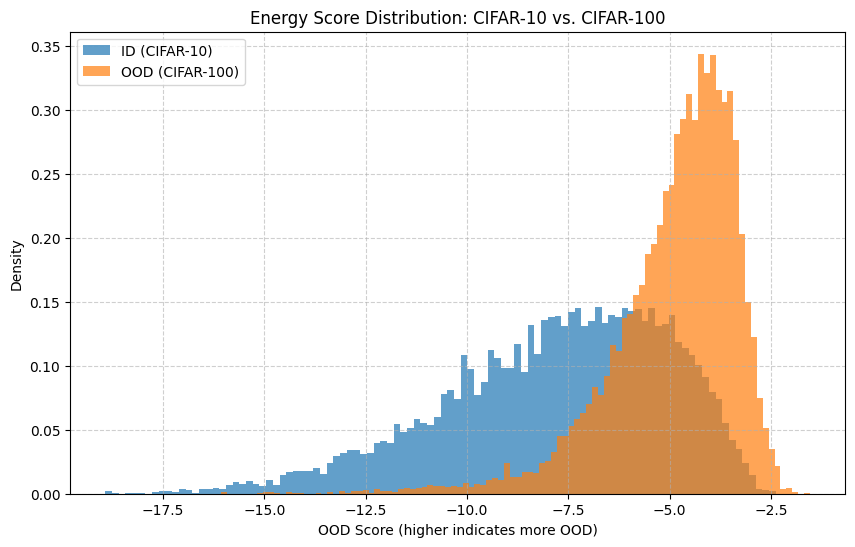

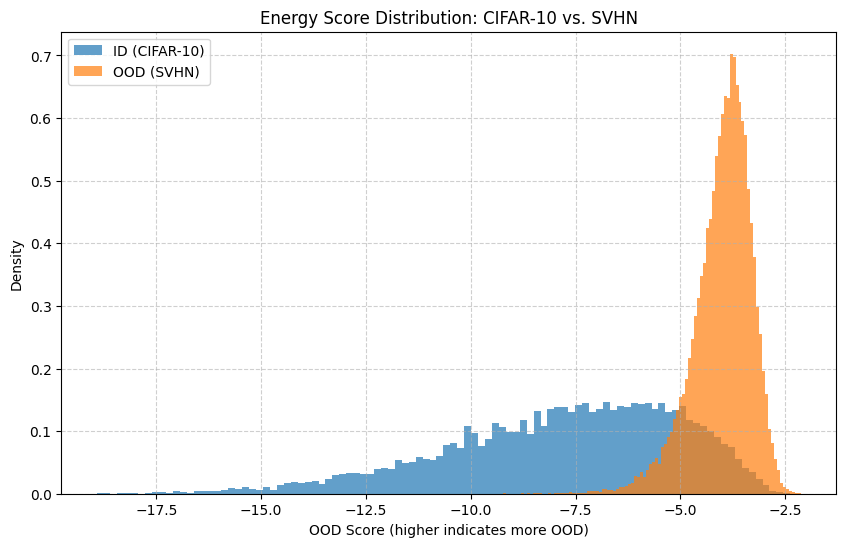

In [37]:
def plot_histograms(id_scores, ood_scores, id_label, ood_label, title):
    plt.figure(figsize=(10, 6))
    plt.hist(id_scores, bins=100, alpha=0.7, density=True, label=id_label)
    plt.hist(ood_scores, bins=100, alpha=0.7, density=True, label=ood_label)
    plt.xlabel("OOD Score (higher indicates more OOD)")
    plt.ylabel("Density")
    plt.title(title)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()

plot_histograms(id_scores, ood_scores_cifar100,
                "ID (CIFAR-10)", "OOD (CIFAR-100)",
                "Energy Score Distribution: CIFAR-10 vs. CIFAR-100")

plot_histograms(id_scores, ood_scores_svhn,
                "ID (CIFAR-10)", "OOD (SVHN)",
                "Energy Score Distribution: CIFAR-10 vs. SVHN")

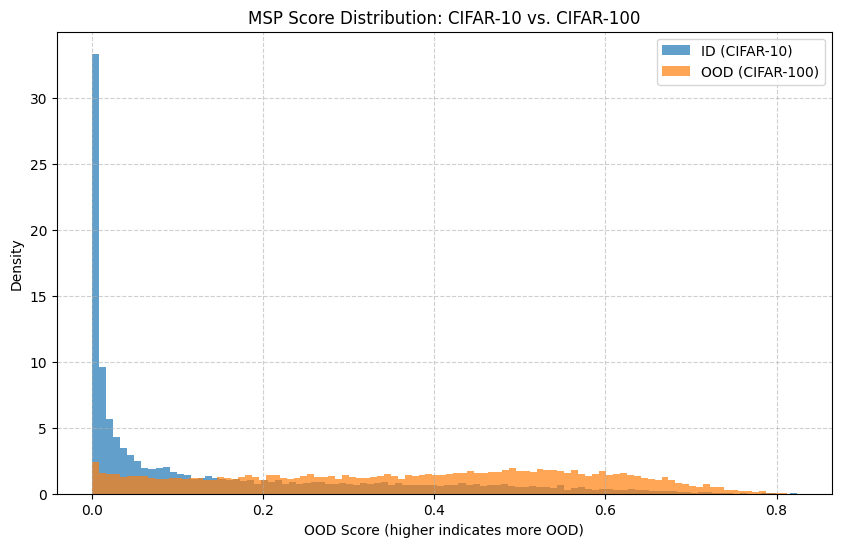

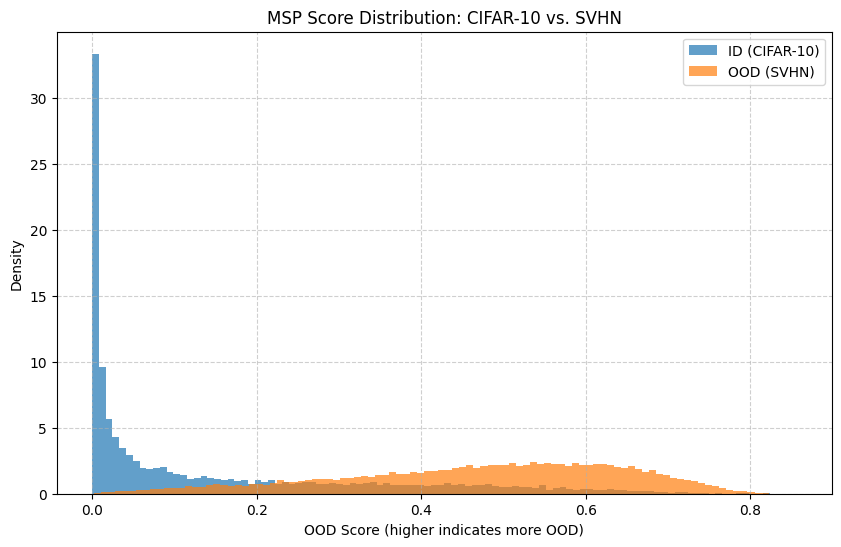

In [38]:
plot_histograms(id_scores_msp, ood_scores_cifar100_msp,
                "ID (CIFAR-10)", "OOD (CIFAR-100)",
                "MSP Score Distribution: CIFAR-10 vs. CIFAR-100")

plot_histograms(id_scores_msp, ood_scores_svhn_msp,
                "ID (CIFAR-10)", "OOD (SVHN)",
                "MSP Score Distribution: CIFAR-10 vs. SVHN")

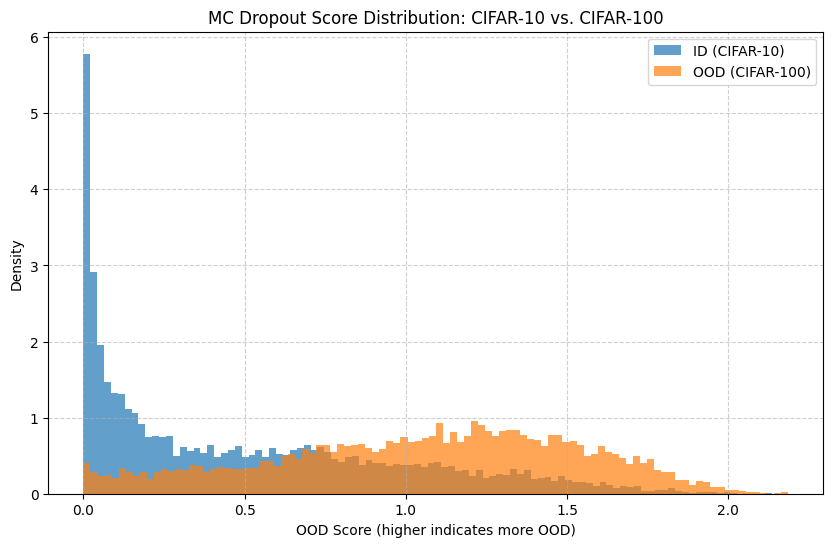

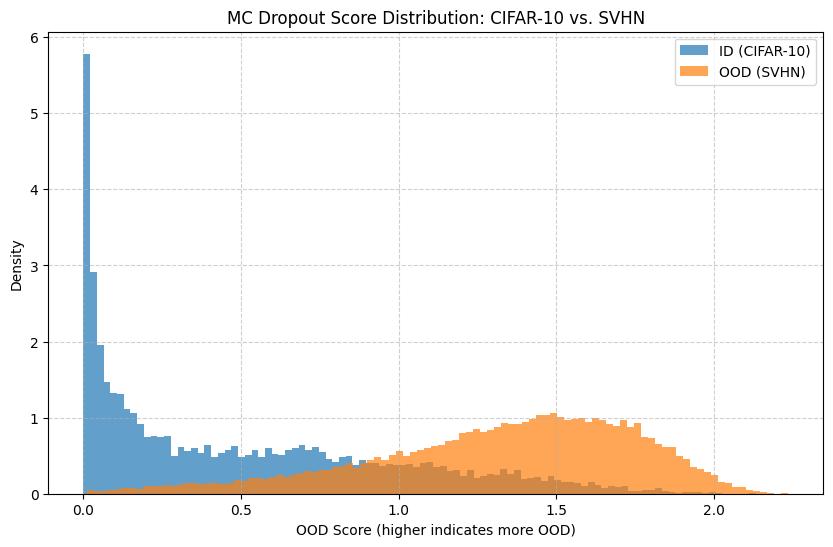

In [39]:
plot_histograms(id_scores_mcd, ood_scores_cifar100_mcd,
                "ID (CIFAR-10)", "OOD (CIFAR-100)",
                "MC Dropout Score Distribution: CIFAR-10 vs. CIFAR-100")

plot_histograms(id_scores_mcd, ood_scores_svhn_mcd,
                "ID (CIFAR-10)", "OOD (SVHN)",
                "MC Dropout Score Distribution: CIFAR-10 vs. SVHN")


--- Plotting Deep Ensemble Score Distributions ---


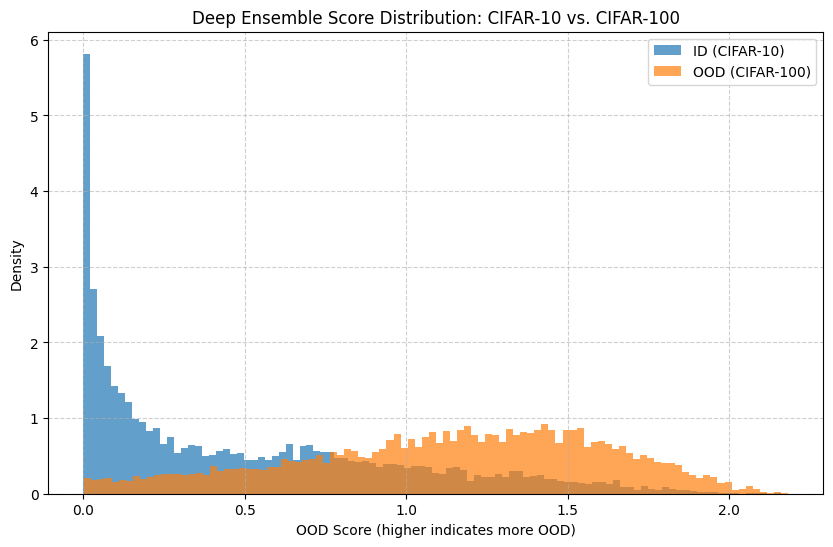

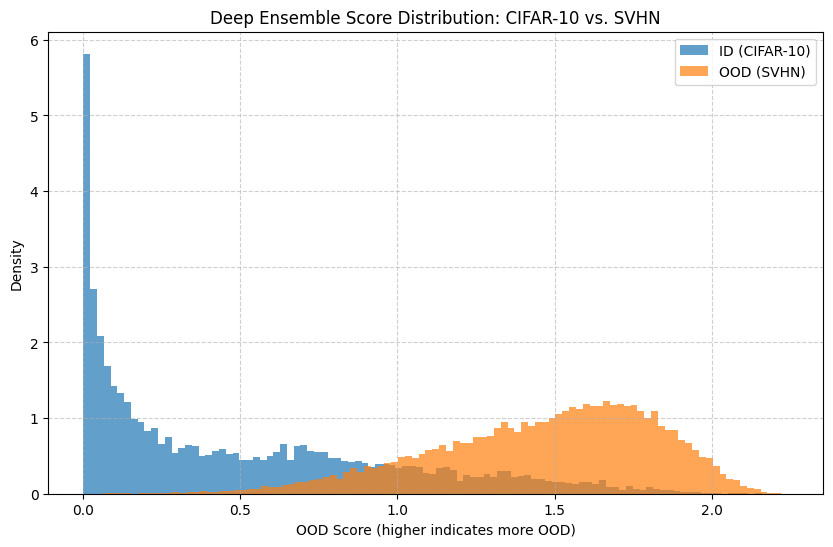

In [40]:
print("\n--- Plotting Deep Ensemble Score Distributions ---")
plot_histograms(id_scores_ensemble, ood_scores_cifar100_ensemble,
                "ID (CIFAR-10)", "OOD (CIFAR-100)",
                "Deep Ensemble Score Distribution: CIFAR-10 vs. CIFAR-100")

plot_histograms(id_scores_ensemble, ood_scores_svhn_ensemble,
                "ID (CIFAR-10)", "OOD (SVHN)",
                "Deep Ensemble Score Distribution: CIFAR-10 vs. SVHN")

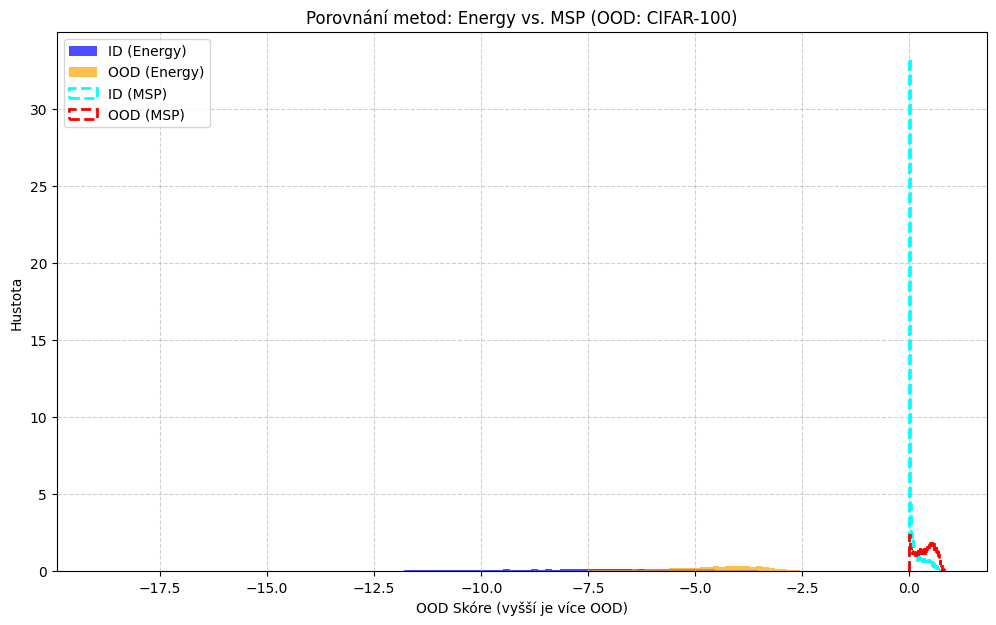

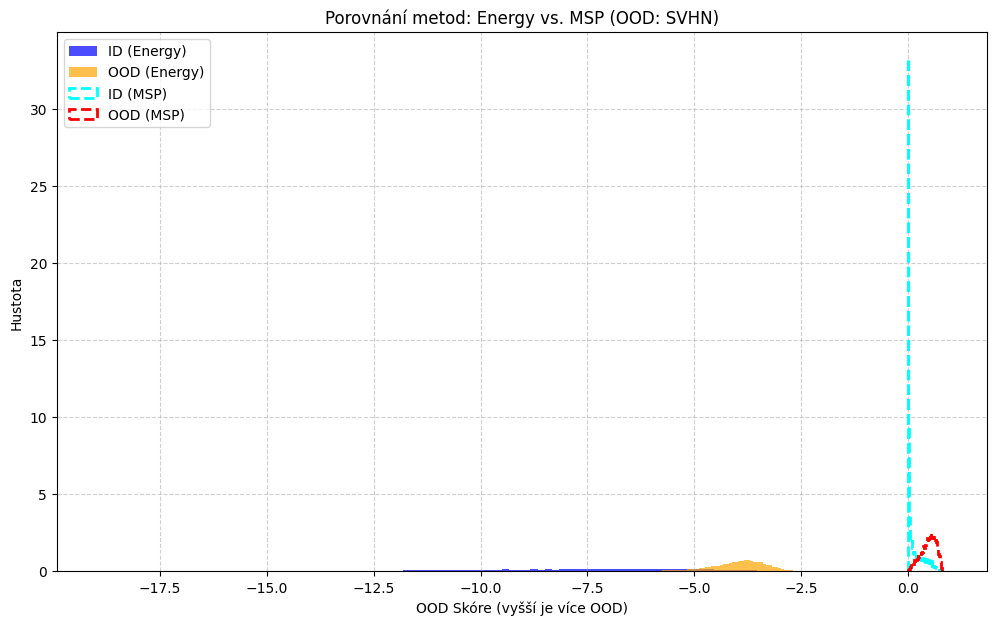

In [41]:
def plot_comparison_histograms(id_scores_1, ood_scores_1, label_1,
                               id_scores_2, ood_scores_2, label_2,
                               title):
    plt.figure(figsize=(12, 7))

    plt.hist(id_scores_1, bins=100, alpha=0.7, density=True, label=f"ID ({label_1})", color='blue')
    plt.hist(ood_scores_1, bins=100, alpha=0.7, density=True, label=f"OOD ({label_1})", color='orange')

    plt.hist(id_scores_2, bins=100, density=True, label=f"ID ({label_2})", histtype='step', linewidth=2, linestyle='--', color='cyan')
    plt.hist(ood_scores_2, bins=100, density=True, label=f"OOD ({label_2})", histtype='step', linewidth=2, linestyle='--', color='red')

    plt.xlabel("OOD Skóre (vyšší je více OOD)")
    plt.ylabel("Hustota")
    plt.title(title)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()

plot_comparison_histograms(id_scores, ood_scores_cifar100, "Energy",
                           id_scores_msp, ood_scores_cifar100_msp, "MSP",
                           "Porovnání metod: Energy vs. MSP (OOD: CIFAR-100)")

plot_comparison_histograms(id_scores, ood_scores_svhn, "Energy",
                           id_scores_msp, ood_scores_svhn_msp, "MSP",
                           "Porovnání metod: Energy vs. MSP (OOD: SVHN)")

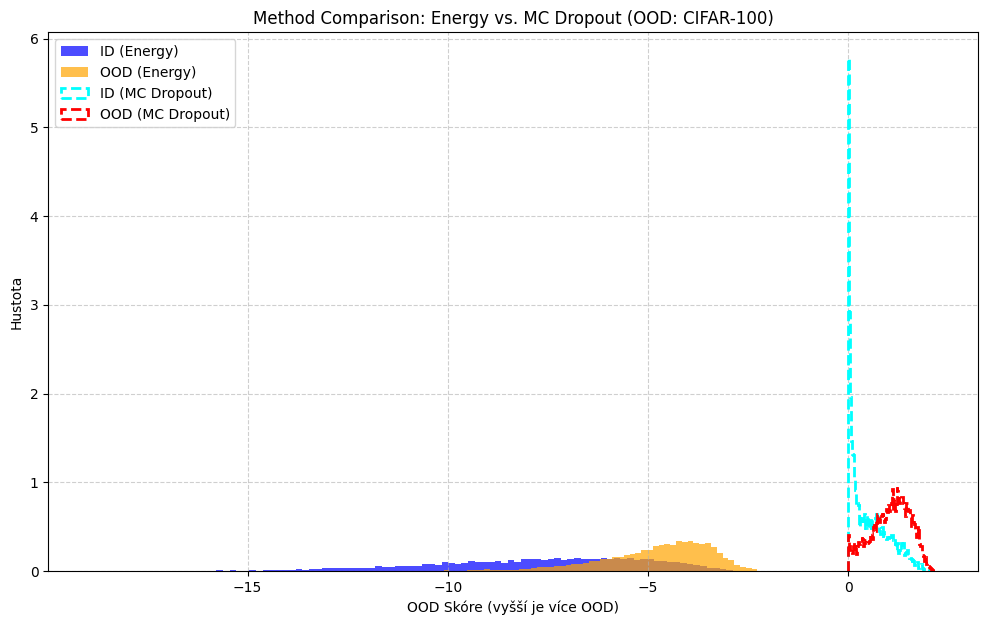

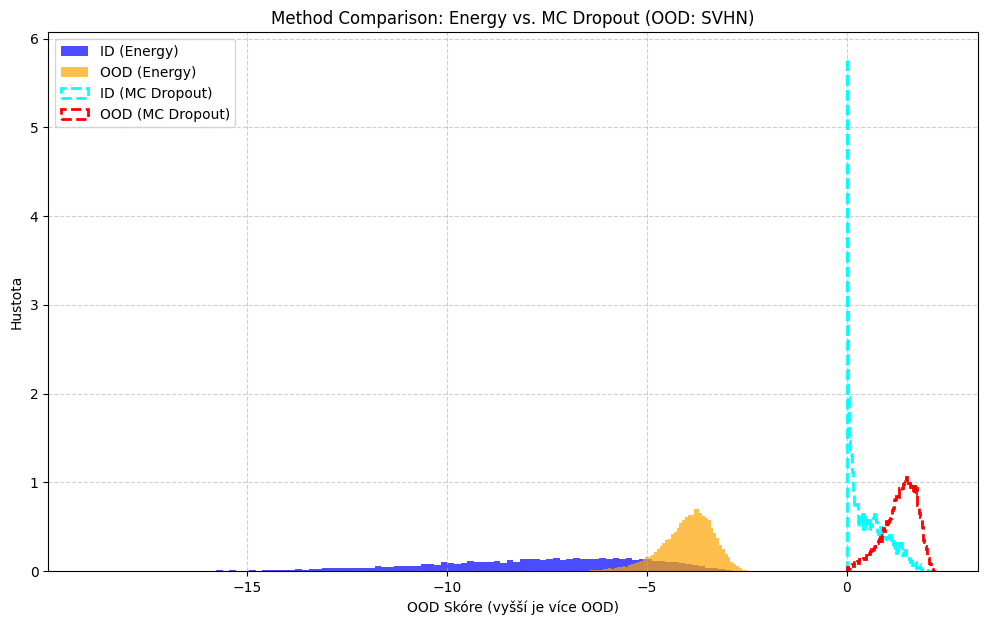

In [44]:
plot_comparison_histograms(id_scores, ood_scores_cifar100, "Energy",
                           id_scores_mcd, ood_scores_cifar100_mcd, "MC Dropout",
                           "Method Comparison: Energy vs. MC Dropout (OOD: CIFAR-100)")

# Comparison on OOD dataset SVHN
plot_comparison_histograms(id_scores, ood_scores_svhn, "Energy",
                           id_scores_mcd, ood_scores_svhn_mcd, "MC Dropout",
                           "Method Comparison: Energy vs. MC Dropout (OOD: SVHN)")

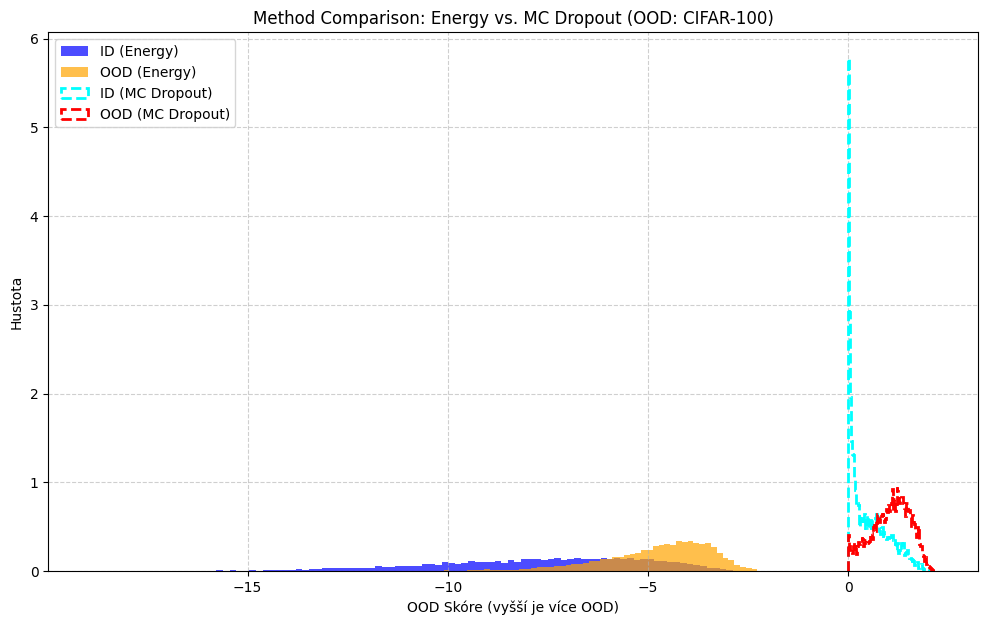

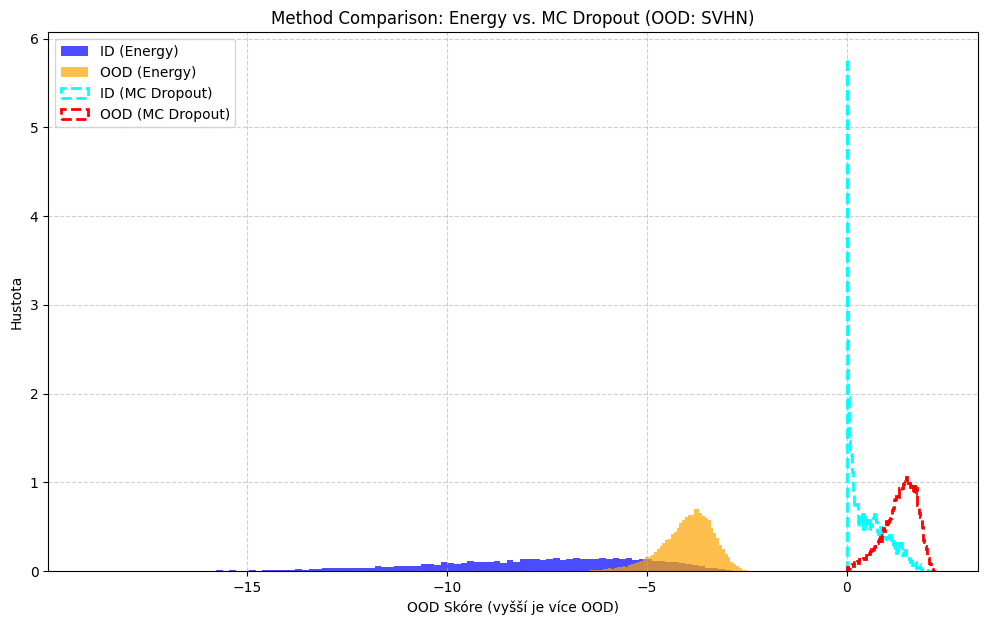

In [43]:
plot_comparison_histograms(id_scores, ood_scores_cifar100, "Energy",
                           id_scores_mcd, ood_scores_cifar100_mcd, "MC Dropout",
                           "Method Comparison: Energy vs. MC Dropout (OOD: CIFAR-100)")

# Comparison on OOD dataset SVHN
plot_comparison_histograms(id_scores, ood_scores_svhn, "Energy",
                           id_scores_mcd, ood_scores_svhn_mcd, "MC Dropout",
                           "Method Comparison: Energy vs. MC Dropout (OOD: SVHN)")